
Nonlinear model - learning rate 0.1
Epoch  500 | Training loss: 2.090720
Epoch 1000 | Training loss: 2.090720
Epoch 1500 | Training loss: 2.090720
Epoch 2000 | Training loss: 2.090720
Epoch 2500 | Training loss: 2.090720
Epoch 3000 | Training loss: 2.090720
Epoch 3500 | Training loss: 2.090720
Epoch 4000 | Training loss: 2.090720
Epoch 4500 | Training loss: 2.090720
Epoch 5000 | Training loss: 2.090720

Nonlinear model - learning rate 0.01
Epoch  500 | Training loss: 2.091741
Epoch 1000 | Training loss: 2.090720
Epoch 1500 | Training loss: 2.090720
Epoch 2000 | Training loss: 2.090720
Epoch 2500 | Training loss: 2.090720
Epoch 3000 | Training loss: 2.090720
Epoch 3500 | Training loss: 2.090720
Epoch 4000 | Training loss: 2.090720
Epoch 4500 | Training loss: 2.090720
Epoch 5000 | Training loss: 2.090720

Nonlinear model - learning rate 0.001
Epoch  500 | Training loss: 25.472828
Epoch 1000 | Training loss: 7.689431
Epoch 1500 | Training loss: 3.727663
Epoch 2000 | Training loss: 2.6273

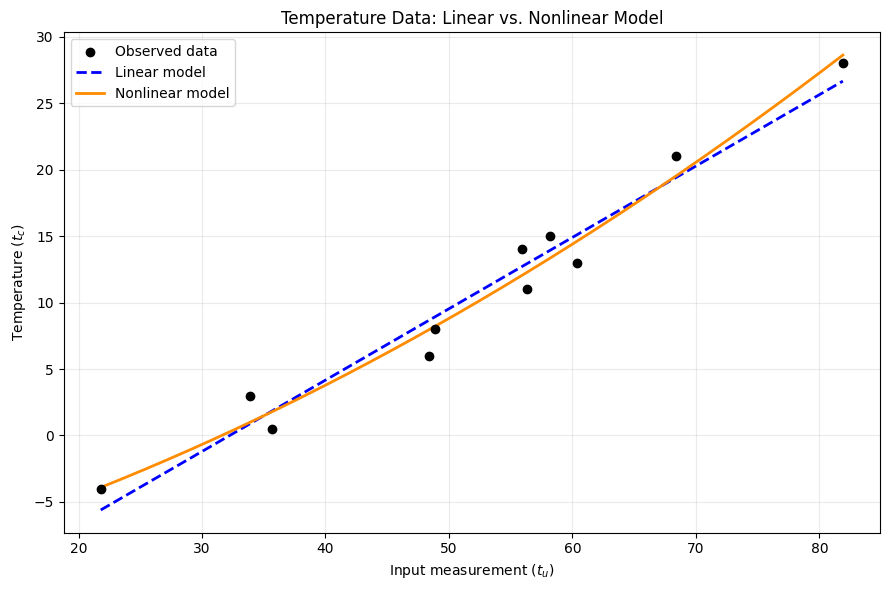

Mounted at /content/drive
Loaded housing data from: /content/drive/MyDrive/Courses/Intro-to-ML/Datasets/Housing.csv
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no   

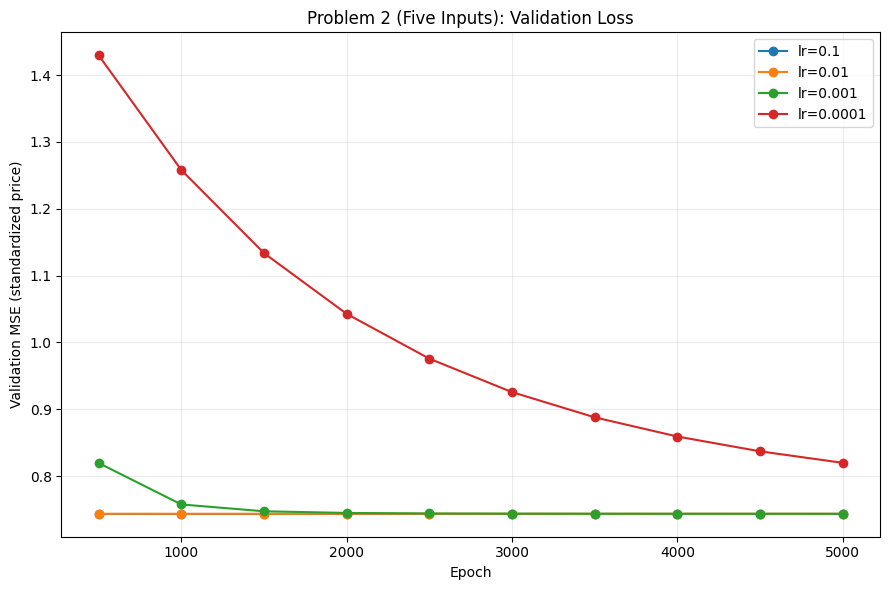

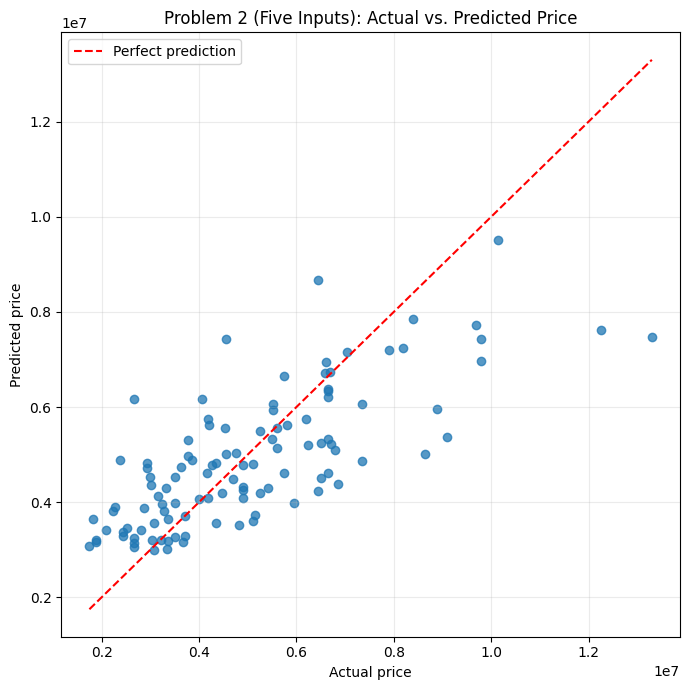


Problem 2 comparison with the Homework 2 baseline:
                                 model  validation_mse  validation_r2_percent
Homework 2 / sklearn linear regression    2.292722e+12              54.640615
                  Homework 5 / PyTorch    2.292722e+12              54.640615

Problem 3 - learning rate 0.1
Epoch  500 | Loss 0.314056 | Validation loss 0.568957 | Validation accuracy (R^2) 65.29%


/tmp/ipykernel_2281/1091426068.py:910: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  housing_all[binary_features].replace(


Epoch 1000 | Loss 0.314056 | Validation loss 0.568957 | Validation accuracy (R^2) 65.29%
Epoch 1500 | Loss 0.314056 | Validation loss 0.568957 | Validation accuracy (R^2) 65.29%
Epoch 2000 | Loss 0.314056 | Validation loss 0.568957 | Validation accuracy (R^2) 65.29%
Epoch 2500 | Loss 0.314056 | Validation loss 0.568957 | Validation accuracy (R^2) 65.29%
Epoch 3000 | Loss 0.314056 | Validation loss 0.568957 | Validation accuracy (R^2) 65.29%
Epoch 3500 | Loss 0.314056 | Validation loss 0.568957 | Validation accuracy (R^2) 65.29%
Epoch 4000 | Loss 0.314056 | Validation loss 0.568957 | Validation accuracy (R^2) 65.29%
Epoch 4500 | Loss 0.314056 | Validation loss 0.568957 | Validation accuracy (R^2) 65.29%
Epoch 5000 | Loss 0.314056 | Validation loss 0.568957 | Validation accuracy (R^2) 65.29%

Problem 3 - learning rate 0.01
Epoch  500 | Loss 0.314058 | Validation loss 0.568770 | Validation accuracy (R^2) 65.30%
Epoch 1000 | Loss 0.314056 | Validation loss 0.568956 | Validation accuracy (R

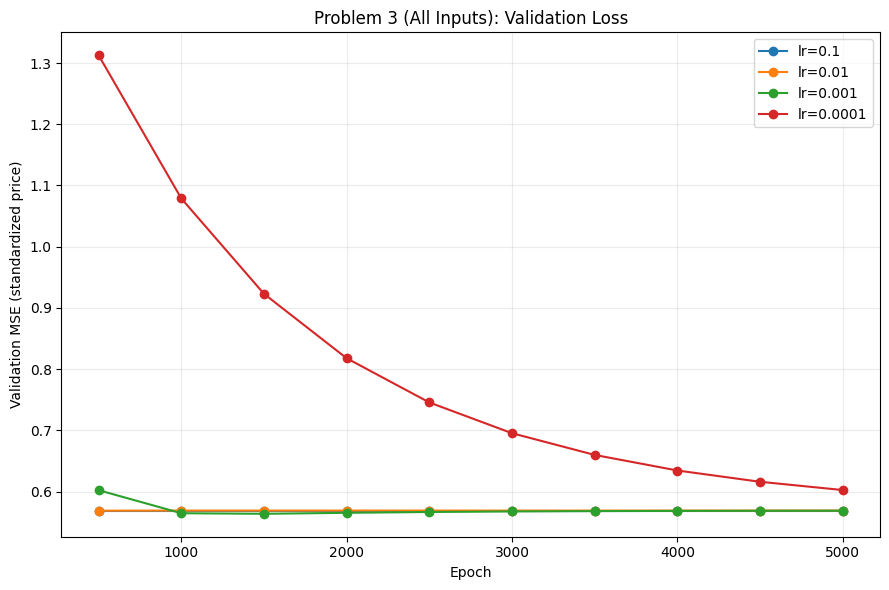

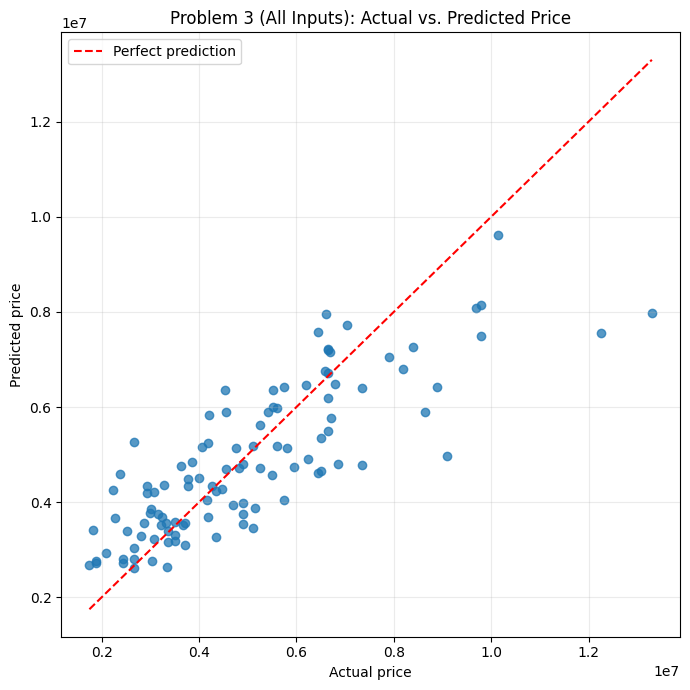


Problem 3 comparison with the Homework 2 baseline:
                                 model  validation_mse  validation_r2_percent
Homework 2 / sklearn linear regression    1.754319e+12              65.292430
                  Homework 5 / PyTorch    1.753727e+12              65.304136

Best-model comparison:
                 model  best_learning_rate  validation_mse  validation_r2_percent
Problem 2: five inputs               0.100    2.292722e+12              54.640615
 Problem 3: all inputs               0.001    1.753727e+12              65.304136


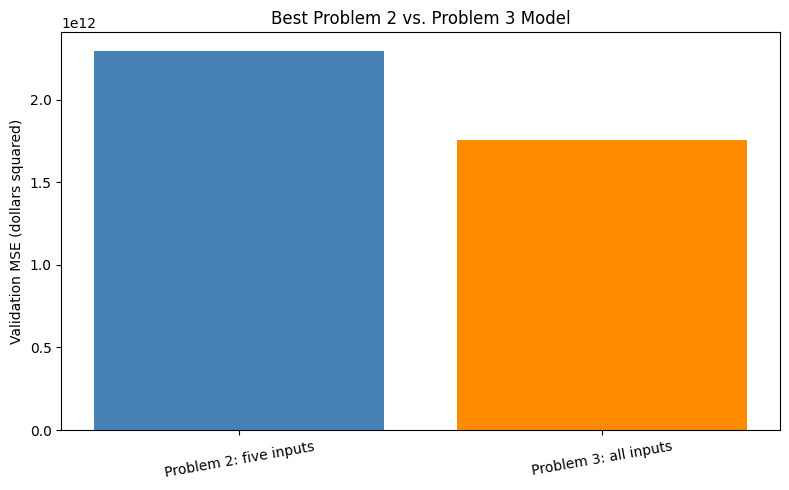

In [ ]:
# Homework 5 - Gabriel Almodovar
# Problems 1, 2, and 3

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.optim as optim

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
np.random.seed(42)


# ============================================================
# PROBLEM 1 - NONLINEAR TEMPERATURE MODEL
# ============================================================

t_c = torch.tensor(
    [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0],
    dtype=torch.float32,
)

t_u = torch.tensor(
    [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4],
    dtype=torch.float32,
)

# Standardize the input so all four learning rates remain stable.
t_u_mean = t_u.mean()
t_u_std = t_u.std(unbiased=False)
t_un = (t_u - t_u_mean) / t_u_std


def nonlinear_model(t_u_normalized, w2, w1, b):
    return w2 * t_u_normalized**2 + w1 * t_u_normalized + b


def linear_model(t_u_normalized, w, b):
    return w * t_u_normalized + b


def loss_fn(t_p, t_c):
    return ((t_p - t_c) ** 2).mean()


def train_temperature_model(
    model_fn,
    initial_params,
    learning_rate,
    n_epochs=5000,
    print_results=True,
):
    params = initial_params.clone().detach().requires_grad_(True)
    optimizer = optim.SGD([params], lr=learning_rate)
    history = []

    for epoch in range(1, n_epochs + 1):
        prediction = model_fn(t_un, *params)
        loss = loss_fn(prediction, t_c)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            with torch.no_grad():
                checkpoint_loss = loss_fn(
                    model_fn(t_un, *params),
                    t_c,
                ).item()

            history.append(
                {
                    "epoch": epoch,
                    "training_loss": checkpoint_loss,
                }
            )

            if print_results:
                print(
                    f"Epoch {epoch:4d} | "
                    f"Training loss: {checkpoint_loss:.6f}"
                )

    with torch.no_grad():
        final_loss = loss_fn(
            model_fn(t_un, *params),
            t_c,
        ).item()

    return {
        "params": params.detach().clone(),
        "history": pd.DataFrame(history),
        "final_loss": final_loss,
    }


# ------------------------------------------------------------
# Problem 1.a and 1.b
# Four nonlinear training sessions
# ------------------------------------------------------------

learning_rates = [0.1, 0.01, 0.001, 0.0001]
nonlinear_runs = {}

for learning_rate in learning_rates:
    print("\n" + "=" * 60)
    print(f"Nonlinear model - learning rate {learning_rate}")
    print("=" * 60)

    nonlinear_runs[learning_rate] = train_temperature_model(
        model_fn=nonlinear_model,
        initial_params=torch.tensor([0.0, 0.0, 0.0]),
        learning_rate=learning_rate,
        n_epochs=5000,
    )

nonlinear_summary = pd.DataFrame(
    {
        "learning_rate": learning_rates,
        "final_training_loss": [
            nonlinear_runs[lr]["final_loss"]
            for lr in learning_rates
        ],
    }
).sort_values(
    "final_training_loss",
    ignore_index=True,
)

print("\nProblem 1 nonlinear model summary:")
print(nonlinear_summary.to_string(index=False))

best_nonlinear_lr = float(
    nonlinear_summary.loc[0, "learning_rate"]
)

best_nonlinear = nonlinear_runs[best_nonlinear_lr]
best_nonlinear_params = best_nonlinear["params"]

# Convert the standardized-input parameters back to:
# w2 * t_u**2 + w1 * t_u + b

w2_normalized = best_nonlinear_params[0].item()
w1_normalized = best_nonlinear_params[1].item()
b_normalized = best_nonlinear_params[2].item()

u_mean = t_u_mean.item()
u_std = t_u_std.item()

w2_original = w2_normalized / (u_std**2)

w1_original = (
    w1_normalized / u_std
    - 2.0 * w2_normalized * u_mean / (u_std**2)
)

b_original = (
    b_normalized
    - w1_normalized * u_mean / u_std
    + w2_normalized * u_mean**2 / (u_std**2)
)

print(f"\nBest nonlinear learning rate: {best_nonlinear_lr}")
print(
    f"Best nonlinear training loss: "
    f"{best_nonlinear['final_loss']:.6f}"
)

print("\nBest nonlinear parameters in original t_u units:")
print(f"w2 = {w2_original:.8f}")
print(f"w1 = {w1_original:.8f}")
print(f"b  = {b_original:.8f}")


# ------------------------------------------------------------
# Problem 1.c
# Compare nonlinear model with the lecture linear model
# ------------------------------------------------------------

linear_run = train_temperature_model(
    model_fn=linear_model,
    initial_params=torch.tensor([0.0, 0.0]),
    learning_rate=0.1,
    n_epochs=5000,
    print_results=False,
)

linear_params = linear_run["params"]

linear_w_original = linear_params[0].item() / u_std

linear_b_original = (
    linear_params[1].item()
    - linear_params[0].item() * u_mean / u_std
)

comparison_p1 = pd.DataFrame(
    {
        "model": [
            "Lecture linear model",
            "Best nonlinear model",
        ],
        "final_training_loss": [
            linear_run["final_loss"],
            best_nonlinear["final_loss"],
        ],
    }
)

comparison_p1["improvement_over_linear_percent"] = (
    (
        linear_run["final_loss"]
        - comparison_p1["final_training_loss"]
    )
    / linear_run["final_loss"]
    * 100.0
)

print("\nProblem 1 model comparison:")
print(comparison_p1.to_string(index=False))

print("\nLinear parameters in original t_u units:")
print(f"w = {linear_w_original:.8f}")
print(f"b = {linear_b_original:.8f}")

if best_nonlinear["final_loss"] < linear_run["final_loss"]:
    print(
        "\nThe nonlinear model is better because it has "
        "a lower final mean squared error."
    )
else:
    print(
        "\nThe nonlinear model is worse because it does "
        "not have a lower final mean squared error."
    )

t_plot = torch.linspace(
    t_u.min(),
    t_u.max(),
    300,
)

t_plot_normalized = (
    t_plot - t_u_mean
) / t_u_std

with torch.no_grad():
    nonlinear_plot = nonlinear_model(
        t_plot_normalized,
        *best_nonlinear_params,
    )

    linear_plot = linear_model(
        t_plot_normalized,
        *linear_params,
    )

plt.figure(figsize=(9, 6))

plt.scatter(
    t_u.numpy(),
    t_c.numpy(),
    color="black",
    label="Observed data",
    zorder=3,
)

plt.plot(
    t_plot.numpy(),
    linear_plot.numpy(),
    "b--",
    linewidth=2,
    label="Linear model",
)

plt.plot(
    t_plot.numpy(),
    nonlinear_plot.numpy(),
    color="darkorange",
    linewidth=2,
    label="Nonlinear model",
)

plt.xlabel("Input measurement ($t_u$)")
plt.ylabel("Temperature ($t_c$)")
plt.title("Temperature Data: Linear vs. Nonlinear Model")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# SHARED FUNCTIONS FOR PROBLEMS 2 AND 3
# ============================================================

def prepare_housing_data(dataframe, feature_names):
    clean_data = dataframe[
        ["price"] + feature_names
    ].dropna().copy()

    X = clean_data[
        feature_names
    ].to_numpy(dtype=np.float32)

    y = clean_data[
        "price"
    ].to_numpy(dtype=np.float32)

    (
        X_train_raw,
        X_val_raw,
        y_train_raw,
        y_val_raw,
    ) = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
    )

    # Fit the scalers using only the training data.
    X_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train_scaled = X_scaler.fit_transform(
        X_train_raw
    )

    X_val_scaled = X_scaler.transform(
        X_val_raw
    )

    y_train_scaled = y_scaler.fit_transform(
        y_train_raw.reshape(-1, 1)
    ).ravel()

    y_val_scaled = y_scaler.transform(
        y_val_raw.reshape(-1, 1)
    ).ravel()

    return {
        "feature_names": feature_names,
        "X_train_raw": X_train_raw,
        "X_val_raw": X_val_raw,
        "y_train_raw": y_train_raw,
        "y_val_raw": y_val_raw,
        "X_train": torch.tensor(
            X_train_scaled,
            dtype=torch.float32,
        ),
        "X_val": torch.tensor(
            X_val_scaled,
            dtype=torch.float32,
        ),
        "y_train": torch.tensor(
            y_train_scaled,
            dtype=torch.float32,
        ),
        "y_val": torch.tensor(
            y_val_scaled,
            dtype=torch.float32,
        ),
        "X_scaler": X_scaler,
        "y_scaler": y_scaler,
    }


def housing_model(X, weights, bias):
    return X @ weights + bias


def regression_r2(y_true, y_prediction):
    residual_sum = torch.sum(
        (y_true - y_prediction) ** 2
    )

    total_sum = torch.sum(
        (y_true - y_true.mean()) ** 2
    )

    return 1.0 - residual_sum / total_sum


def train_housing_model(
    data,
    learning_rate,
    n_epochs=5000,
):
    number_of_features = data[
        "X_train"
    ].shape[1]

    weights = torch.zeros(
        number_of_features,
        requires_grad=True,
    )

    bias = torch.zeros(
        (),
        requires_grad=True,
    )

    optimizer = optim.SGD(
        [weights, bias],
        lr=learning_rate,
    )

    history = []

    for epoch in range(1, n_epochs + 1):
        train_prediction = housing_model(
            data["X_train"],
            weights,
            bias,
        )

        train_loss = loss_fn(
            train_prediction,
            data["y_train"],
        )

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            with torch.no_grad():
                train_prediction = housing_model(
                    data["X_train"],
                    weights,
                    bias,
                )

                val_prediction = housing_model(
                    data["X_val"],
                    weights,
                    bias,
                )

                train_loss_value = loss_fn(
                    train_prediction,
                    data["y_train"],
                ).item()

                val_loss_value = loss_fn(
                    val_prediction,
                    data["y_val"],
                ).item()

                val_r2_value = regression_r2(
                    data["y_val"],
                    val_prediction,
                ).item()

            history.append(
                {
                    "epoch": epoch,
                    "training_loss": train_loss_value,
                    "validation_loss": val_loss_value,
                    "validation_accuracy_r2_percent":
                        100.0 * val_r2_value,
                }
            )

            print(
                f"Epoch {epoch:4d} | "
                f"Loss {train_loss_value:.6f} | "
                f"Validation loss {val_loss_value:.6f} | "
                f"Validation accuracy (R^2) "
                f"{100.0 * val_r2_value:.2f}%"
            )

    with torch.no_grad():
        train_prediction = housing_model(
            data["X_train"],
            weights,
            bias,
        )

        val_prediction = housing_model(
            data["X_val"],
            weights,
            bias,
        )

        final_train_loss = loss_fn(
            train_prediction,
            data["y_train"],
        ).item()

        final_val_loss = loss_fn(
            val_prediction,
            data["y_val"],
        ).item()

        final_val_r2 = regression_r2(
            data["y_val"],
            val_prediction,
        ).item()

    return {
        "weights": weights.detach().clone(),
        "bias": bias.detach().clone(),
        "history": pd.DataFrame(history),
        "final_train_loss": final_train_loss,
        "final_val_loss": final_val_loss,
        "final_val_r2": final_val_r2,
    }


def run_four_housing_sessions(
    data,
    problem_name,
):
    runs = {}

    for learning_rate in learning_rates:
        print("\n" + "=" * 60)
        print(
            f"{problem_name} - "
            f"learning rate {learning_rate}"
        )
        print("=" * 60)

        runs[learning_rate] = train_housing_model(
            data=data,
            learning_rate=learning_rate,
            n_epochs=5000,
        )

    rows = []

    for learning_rate, run in runs.items():
        with torch.no_grad():
            validation_scaled = housing_model(
                data["X_val"],
                run["weights"],
                run["bias"],
            ).numpy()

        validation_price = (
            data["y_scaler"]
            .inverse_transform(
                validation_scaled.reshape(-1, 1)
            )
            .ravel()
        )

        rows.append(
            {
                "learning_rate": learning_rate,
                "final_training_loss_scaled":
                    run["final_train_loss"],
                "final_validation_loss_scaled":
                    run["final_val_loss"],
                "validation_mse_dollars_squared":
                    mean_squared_error(
                        data["y_val_raw"],
                        validation_price,
                    ),
                "validation_accuracy_r2_percent":
                    100.0 * r2_score(
                        data["y_val_raw"],
                        validation_price,
                    ),
            }
        )

    summary = pd.DataFrame(rows).sort_values(
        "final_validation_loss_scaled",
        ignore_index=True,
    )

    best_learning_rate = float(
        summary.loc[0, "learning_rate"]
    )

    return runs, summary, best_learning_rate


def original_unit_parameters(data, run):
    scaled_weights = run[
        "weights"
    ].numpy()

    scaled_bias = run[
        "bias"
    ].item()

    x_mean = data[
        "X_scaler"
    ].mean_

    x_scale = data[
        "X_scaler"
    ].scale_

    y_mean = data[
        "y_scaler"
    ].mean_[0]

    y_scale = data[
        "y_scaler"
    ].scale_[0]

    original_weights = (
        y_scale
        * scaled_weights
        / x_scale
    )

    original_bias = (
        y_mean
        + y_scale * scaled_bias
        - np.sum(original_weights * x_mean)
    )

    return pd.DataFrame(
        {
            "parameter":
                data["feature_names"]
                + ["intercept"],
            "value":
                list(original_weights)
                + [original_bias],
        }
    )


def predict_prices(data, run):
    with torch.no_grad():
        prediction_scaled = housing_model(
            data["X_val"],
            run["weights"],
            run["bias"],
        ).numpy()

    return (
        data["y_scaler"]
        .inverse_transform(
            prediction_scaled.reshape(-1, 1)
        )
        .ravel()
    )


def plot_housing_results(
    data,
    runs,
    best_learning_rate,
    title_prefix,
):
    plt.figure(figsize=(9, 6))

    for learning_rate, run in runs.items():
        plt.plot(
            run["history"]["epoch"],
            run["history"]["validation_loss"],
            marker="o",
            label=f"lr={learning_rate}",
        )

    plt.xlabel("Epoch")
    plt.ylabel(
        "Validation MSE (standardized price)"
    )
    plt.title(
        f"{title_prefix}: Validation Loss"
    )
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

    best_prediction = predict_prices(
        data,
        runs[best_learning_rate],
    )

    minimum_price = min(
        data["y_val_raw"].min(),
        best_prediction.min(),
    )

    maximum_price = max(
        data["y_val_raw"].max(),
        best_prediction.max(),
    )

    plt.figure(figsize=(7, 7))

    plt.scatter(
        data["y_val_raw"],
        best_prediction,
        alpha=0.75,
    )

    plt.plot(
        [minimum_price, maximum_price],
        [minimum_price, maximum_price],
        "r--",
        label="Perfect prediction",
    )

    plt.xlabel("Actual price")
    plt.ylabel("Predicted price")
    plt.title(
        f"{title_prefix}: Actual vs. Predicted Price"
    )
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()


def compare_with_homework2_baseline(
    data,
    pytorch_prediction,
    problem_name,
):
    # Ordinary least-squares linear regression baseline.
    baseline = LinearRegression()

    baseline.fit(
        data["X_train_raw"],
        data["y_train_raw"],
    )

    baseline_prediction = baseline.predict(
        data["X_val_raw"]
    )

    comparison = pd.DataFrame(
        {
            "model": [
                "Homework 2 / sklearn linear regression",
                "Homework 5 / PyTorch",
            ],
            "validation_mse": [
                mean_squared_error(
                    data["y_val_raw"],
                    baseline_prediction,
                ),
                mean_squared_error(
                    data["y_val_raw"],
                    pytorch_prediction,
                ),
            ],
            "validation_r2_percent": [
                100.0 * r2_score(
                    data["y_val_raw"],
                    baseline_prediction,
                ),
                100.0 * r2_score(
                    data["y_val_raw"],
                    pytorch_prediction,
                ),
            ],
        }
    )

    print(
        f"\n{problem_name} comparison "
        "with the Homework 2 baseline:"
    )

    print(comparison.to_string(index=False))

    return comparison


# ============================================================
# LOAD HOUSING DATA
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

housing_paths = [
    "/content/drive/MyDrive/Courses/Intro-to-ML/Datasets/Housing.csv",
    "/content/drive/My Drive/Courses/Intro-to-ML/Datasets/Housing.csv",
    "/content/Housing.csv",
]

housing_path = next(
    (path for path in housing_paths if os.path.exists(path)),
    None,
)

if housing_path is not None:
    housing = pd.read_csv(housing_path)
    print(f"Loaded housing data from: {housing_path}")
else:
    # Use the dataset directly from the professor's GitHub repository.
    housing_url = (
        "https://raw.githubusercontent.com/"
        "HamedTabkhi/Intro-to-ML/main/Dataset/Housing.csv"
    )
    housing = pd.read_csv(housing_url)
    print(f"Loaded housing data from: {housing_url}")

print(housing.head())
print(f"\nDataset shape: {housing.shape}")


# ============================================================
# PROBLEM 2
# FIVE INPUTS AND SIX PARAMETERS INCLUDING THE BIAS
# ============================================================

problem2_features = [
    "area",
    "bedrooms",
    "bathrooms",
    "stories",
    "parking",
]

problem2_data = prepare_housing_data(
    housing,
    problem2_features,
)

(
    problem2_runs,
    problem2_summary,
    best_problem2_lr,
) = run_four_housing_sessions(
    problem2_data,
    "Problem 2",
)

print(
    "\nProblem 2 summary "
    "(best validation loss first):"
)

print(problem2_summary.to_string(index=False))

print(
    f"\nBest Problem 2 learning rate: "
    f"{best_problem2_lr}"
)

best_problem2_run = problem2_runs[
    best_problem2_lr
]

problem2_parameters = original_unit_parameters(
    problem2_data,
    best_problem2_run,
)

print(
    "\nBest Problem 2 parameters "
    "in original dollar/input units:"
)

print(
    problem2_parameters.to_string(index=False)
)

plot_housing_results(
    problem2_data,
    problem2_runs,
    best_problem2_lr,
    "Problem 2 (Five Inputs)",
)

problem2_prediction = predict_prices(
    problem2_data,
    best_problem2_run,
)

problem2_hw2_comparison = (
    compare_with_homework2_baseline(
        problem2_data,
        problem2_prediction,
        "Problem 2",
    )
)


# ============================================================
# PROBLEM 3
# USE ALL INPUT FEATURES
# ============================================================

housing_all = housing.copy()

binary_features = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea",
]

housing_all[binary_features] = (
    housing_all[binary_features].replace(
        {
            "yes": 1.0,
            "no": 0.0,
        }
    )
)

# Use two dummy variables for furnishing status.
# The dropped category becomes the reference category.
housing_all = pd.get_dummies(
    housing_all,
    columns=["furnishingstatus"],
    drop_first=True,
    dtype=float,
)

problem3_features = [
    column
    for column in housing_all.columns
    if column != "price"
]

problem3_data = prepare_housing_data(
    housing_all,
    problem3_features,
)

(
    problem3_runs,
    problem3_summary,
    best_problem3_lr,
) = run_four_housing_sessions(
    problem3_data,
    "Problem 3",
)

print("\nProblem 3 input features:")
print(problem3_features)

print(
    "\nProblem 3 summary "
    "(best validation loss first):"
)

print(problem3_summary.to_string(index=False))

print(
    f"\nBest Problem 3 learning rate: "
    f"{best_problem3_lr}"
)

best_problem3_run = problem3_runs[
    best_problem3_lr
]

problem3_parameters = original_unit_parameters(
    problem3_data,
    best_problem3_run,
)

print(
    "\nBest Problem 3 parameters "
    "in original dollar/input units:"
)

print(
    problem3_parameters.to_string(index=False)
)

plot_housing_results(
    problem3_data,
    problem3_runs,
    best_problem3_lr,
    "Problem 3 (All Inputs)",
)

problem3_prediction = predict_prices(
    problem3_data,
    best_problem3_run,
)

problem3_hw2_comparison = (
    compare_with_homework2_baseline(
        problem3_data,
        problem3_prediction,
        "Problem 3",
    )
)


# ============================================================
# FINAL PROBLEM 2 VS. PROBLEM 3 COMPARISON
# ============================================================

best_models_comparison = pd.DataFrame(
    {
        "model": [
            "Problem 2: five inputs",
            "Problem 3: all inputs",
        ],
        "best_learning_rate": [
            best_problem2_lr,
            best_problem3_lr,
        ],
        "validation_mse": [
            mean_squared_error(
                problem2_data["y_val_raw"],
                problem2_prediction,
            ),
            mean_squared_error(
                problem3_data["y_val_raw"],
                problem3_prediction,
            ),
        ],
        "validation_r2_percent": [
            100.0 * r2_score(
                problem2_data["y_val_raw"],
                problem2_prediction,
            ),
            100.0 * r2_score(
                problem3_data["y_val_raw"],
                problem3_prediction,
            ),
        ],
    }
)

print("\nBest-model comparison:")
print(
    best_models_comparison.to_string(index=False)
)

plt.figure(figsize=(8, 5))

plt.bar(
    best_models_comparison["model"],
    best_models_comparison["validation_mse"],
    color=["steelblue", "darkorange"],
)

plt.ylabel(
    "Validation MSE (dollars squared)"
)
plt.title(
    "Best Problem 2 vs. Problem 3 Model"
)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()